# 05 - Robustness Lab
Test-time perturbations of a **fixed tuned model** (noise, missing values, drop top features) and **retraining** under class imbalance. `rel_change` is oriented so negative = worse for every metric. All numbers come from `results/raw/robustness_*.csv` (5 seeds).

In [1]:
import sys, json; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from arena.config import RAW_DIR, SUMMARY_DIR, PRED_DIR
pd.set_option('display.width', 180)
from arena.config import FIG_DIR
import seaborn as sns
rc = pd.read_csv(RAW_DIR/'robustness_clf.csv'); rr = pd.read_csv(RAW_DIR/'robustness_reg.csv')

## Classification: degradation curves (macro-F1 relative change vs. severity)

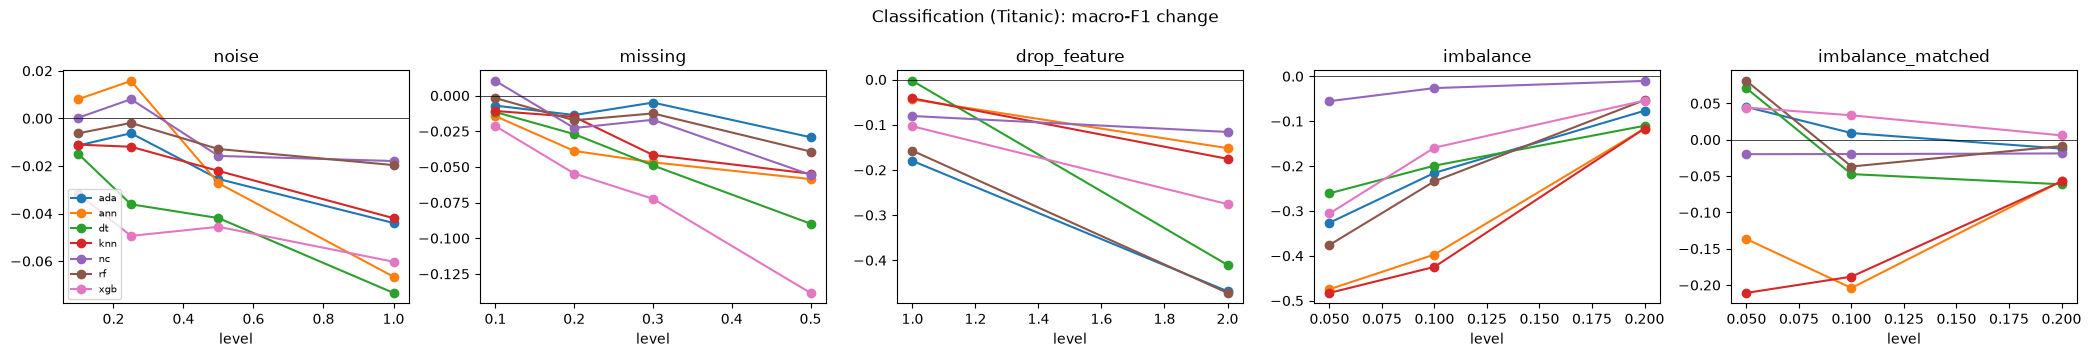

In [2]:
def curves(df, metric, title):
    d = df[df.metric==metric]; fams = d.family.unique()
    fig, axes = plt.subplots(1, len(fams), figsize=(4.2*len(fams), 3.6), squeeze=False)
    for ax, f in zip(axes[0], fams):
        g = d[d.family==f].groupby(['model','level']).rel_change.mean().unstack(0)
        g.plot(ax=ax, marker='o', legend=False); ax.set_title(f); ax.axhline(0, color='k', lw=.5)
    axes[0][0].legend(fontsize=7); fig.suptitle(title); plt.tight_layout(); return fig
fig = curves(rc, 'f1_macro', 'Classification (Titanic): macro-F1 change'); fig.savefig(FIG_DIR/'robustness_clf_curves.png', dpi=130); plt.show()

## Mean relative change per model and family (negative = worse)

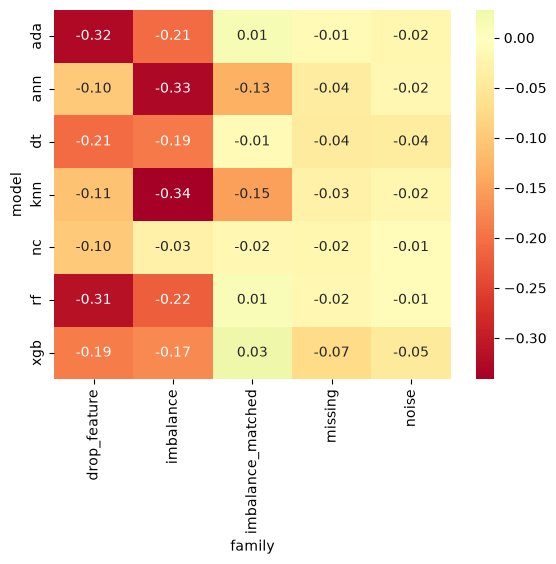

,model,family,metric,mean_rel_change,auc_norm,worst_drop
0,ada,drop_feature,f1_macro,-0.324,0.793,-0.469
1,ada,imbalance,f1_macro,-0.206,0.893,-0.326
2,ada,imbalance_matched,f1_macro,0.014,0.999,-0.012
3,ada,missing,f1_macro,-0.014,0.988,-0.029
4,ada,noise,f1_macro,-0.022,0.976,-0.044
5,ann,drop_feature,f1_macro,-0.098,0.938,-0.152
6,ann,imbalance,f1_macro,-0.330,0.823,-0.475
7,ann,imbalance_matched,f1_macro,-0.133,0.916,-0.204
8,ann,missing,f1_macro,-0.040,0.964,-0.059
9,ann,noise,f1_macro,-0.018,0.978,-0.067


In [3]:
sc = pd.read_csv(SUMMARY_DIR/'robustness_summary_clf.csv')
sns.heatmap(sc.pivot(index='model', columns='family', values='mean_rel_change'), annot=True, fmt='.2f', cmap='RdYlGn', center=0); plt.show()
sc.round(3)

## Is the clean-data winner the most robust? Rank stability vs. baseline ranking

In [4]:
st = pd.read_csv(SUMMARY_DIR/'robustness_rank_stability_clf.csv')
st.assign(clearly_changed=(st.top1_changed) & (st.gap_vs_baseline_winner > st.top1_std)).round(3)

,family,level,metric,kendall_tau,rank_flips,top1,baseline_top1,top1_changed,gap_vs_baseline_winner,top1_std,clearly_changed
0,drop_feature,1.00,f1_macro,0.143,7,dt,xgb,True,0.074,0.026,True
1,drop_feature,2.00,f1_macro,-0.333,7,ann,xgb,True,0.062,0.043,True
2,imbalance,0.05,f1_macro,0.143,6,nc,xgb,True,0.122,0.029,True
3,imbalance,0.10,f1_macro,0.238,5,nc,xgb,True,0.020,0.026,False
4,imbalance,0.20,f1_macro,0.714,5,xgb,xgb,False,0.000,0.020,False
5,imbalance_matched,0.05,f1_macro,0.619,4,rf,xgb,True,0.000,0.106,False
6,imbalance_matched,0.10,f1_macro,0.619,6,xgb,xgb,False,0.000,0.086,False
7,imbalance_matched,0.20,f1_macro,0.905,2,xgb,xgb,False,0.000,0.021,False
8,missing,0.10,f1_macro,0.905,2,rf,xgb,True,0.010,0.005,True
9,missing,0.20,f1_macro,0.619,5,rf,xgb,True,0.025,0.018,True


`clearly_changed` = a different model tops the ranking AND the gap to the old winner exceeds the new winner's seed std. Otherwise a flip may be noise.

## Imbalance: accuracy vs. macro-F1 vs. minority recall (mean over seeds)

In [5]:
im = rc[rc.family=='imbalance'].groupby(['model','level','metric']).perturbed_score.mean().unstack('metric').round(3)
base = rc[rc.family=='noise'].groupby(['model','metric']).baseline_score.mean().unstack('metric').round(3)
print('baseline (original balance)'); print(base); im

baseline (original balance)
metric  accuracy  f1_macro  recall
model                             
ada        0.821     0.809   0.736
ann        0.803     0.788   0.696
dt         0.839     0.825   0.728
knn        0.822     0.808   0.710
nc         0.754     0.741   0.687
rf         0.839     0.828   0.754
xgb        0.846     0.834   0.757


metric       accuracy  f1_macro  recall
model level                            
ada   0.05      0.682     0.543   0.180
      0.10      0.726     0.633   0.299
      0.20      0.789     0.746   0.501
ann   0.05      0.622     0.415   0.038
      0.10      0.648     0.477   0.110
      0.20      0.745     0.693   0.467
dt    0.05      0.711     0.609   0.275
      0.10      0.736     0.661   0.351
      0.20      0.781     0.734   0.475
knn   0.05      0.629     0.417   0.041
      0.10      0.647     0.464   0.093
      0.20      0.769     0.714   0.438
nc    0.05      0.723     0.700   0.597
      0.10      0.739     0.721   0.635
      0.20      0.746     0.733   0.675
rf    0.05      0.668     0.516   0.142
      0.10      0.724     0.634   0.299
      0.20      0.816     0.784   0.562
xgb   0.05      0.695     0.578   0.223
      0.10      0.761     0.701   0.412
      0.20      0.817     0.789   0.588

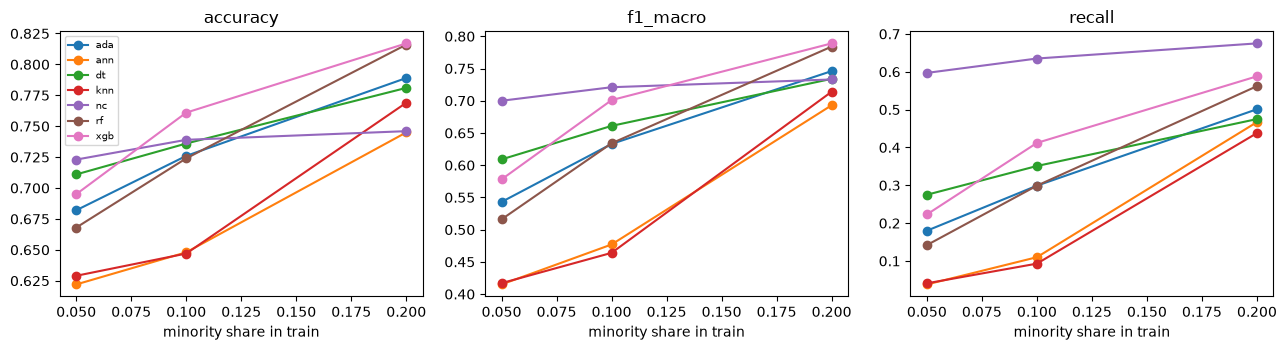

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, m in zip(axes, ['accuracy','f1_macro','recall']):
    im[m].unstack(0).plot(ax=ax, marker='o', legend=False); ax.set_title(m); ax.set_xlabel('minority share in train')
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## Regression (California): RMSE change

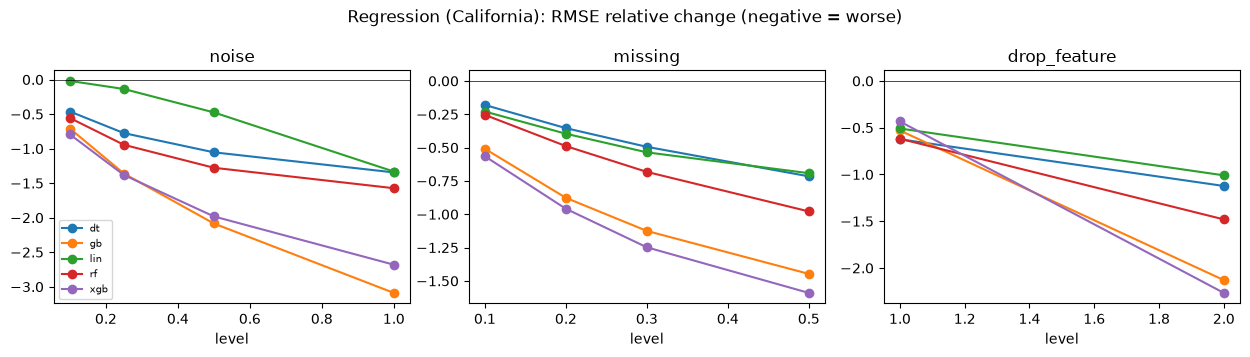

,model,family,metric,mean_rel_change,auc_norm,worst_drop
0,dt,drop_feature,rmse,-0.873,0.676,-1.123
1,dt,missing,rmse,-0.436,0.735,-0.716
2,dt,noise,rmse,-0.909,0.538,-1.344
3,gb,drop_feature,rmse,-1.330,0.657,-2.130
4,gb,missing,rmse,-0.990,0.562,-1.447
5,gb,noise,rmse,-1.811,0.391,-3.089
6,lin,drop_feature,rmse,-0.759,0.706,-1.010
7,lin,missing,rmse,-0.463,0.719,-0.692
8,lin,noise,rmse,-0.491,0.710,-1.332
9,rf,drop_feature,rmse,-1.049,0.660,-1.480


In [7]:
fig = curves(rr, 'rmse', 'Regression (California): RMSE relative change (negative = worse)'); fig.savefig(FIG_DIR/'robustness_reg_curves.png', dpi=130); plt.show()
pd.read_csv(SUMMARY_DIR/'robustness_summary_reg.csv').round(3)

In [8]:
pd.read_csv(SUMMARY_DIR/'robustness_rank_stability_reg.csv').round(3)

,family,level,metric,kendall_tau,rank_flips,top1,baseline_top1,top1_changed,gap_vs_baseline_winner,top1_std
0,drop_feature,1.00,rmse,1.0,0,xgb,xgb,False,0.000,0.012
1,drop_feature,2.00,rmse,-0.2,5,rf,xgb,True,0.220,0.033
2,missing,0.10,rmse,0.4,2,rf,xgb,True,0.072,0.007
3,missing,0.20,rmse,0.0,4,rf,xgb,True,0.132,0.015
4,missing,0.30,rmse,0.0,4,rf,xgb,True,0.164,0.022
5,missing,0.50,rmse,0.0,4,rf,xgb,True,0.169,0.021
6,noise,0.10,rmse,-0.4,5,lin,xgb,True,0.063,0.006
7,noise,0.25,rmse,-0.6,5,lin,xgb,True,0.242,0.004
8,noise,0.50,rmse,-0.6,5,lin,xgb,True,0.264,0.017
9,noise,1.00,rmse,0.0,5,rf,xgb,True,0.360,0.017
